# ScoutIQ Research — Exploratory data analysis

Re-runs the descriptive analysis (`research.analysis.eda`) and displays every audit/EDA figure with its caption. All numbers come from cached StatsBomb Open Data (https://github.com/hudl/open-data) and the documented Transfermarkt crosswalk. Nothing here fits a predictive model; correlations are not causal.

**Pre-requisites:** `python -m research.ingest.audit`, `bash research/ingest/run_all.sh`, `python -m research.ingest.crosswalk`, and the panel builds listed in the README.

In [1]:
import os, sys
os.chdir(os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd())=='notebooks' else os.getcwd())
sys.path.insert(0, os.getcwd())
import pandas as pd
from IPython.display import Image, display
from research.analysis import eda
pd.set_option('display.width', 160)
eda.main()

{'n': 265, 'split_half_r': np.float64(0.6825719768958224), 'spearman_brown_reliability': np.float64(0.8113435695691303), 'sd_pi': np.float64(0.5859235055521794), 'sem': np.float64(0.25449351928393027), 'noise_sd_of_change': np.float64(0.35990818650739304), 'observed_sd_of_change': np.float64(0.35003469491637623), 'signal_share_of_change_variance': 0.0}


## 1. Coverage and continuity (data feasibility)
See `reports/02_data_feasibility.md` for the full tables.

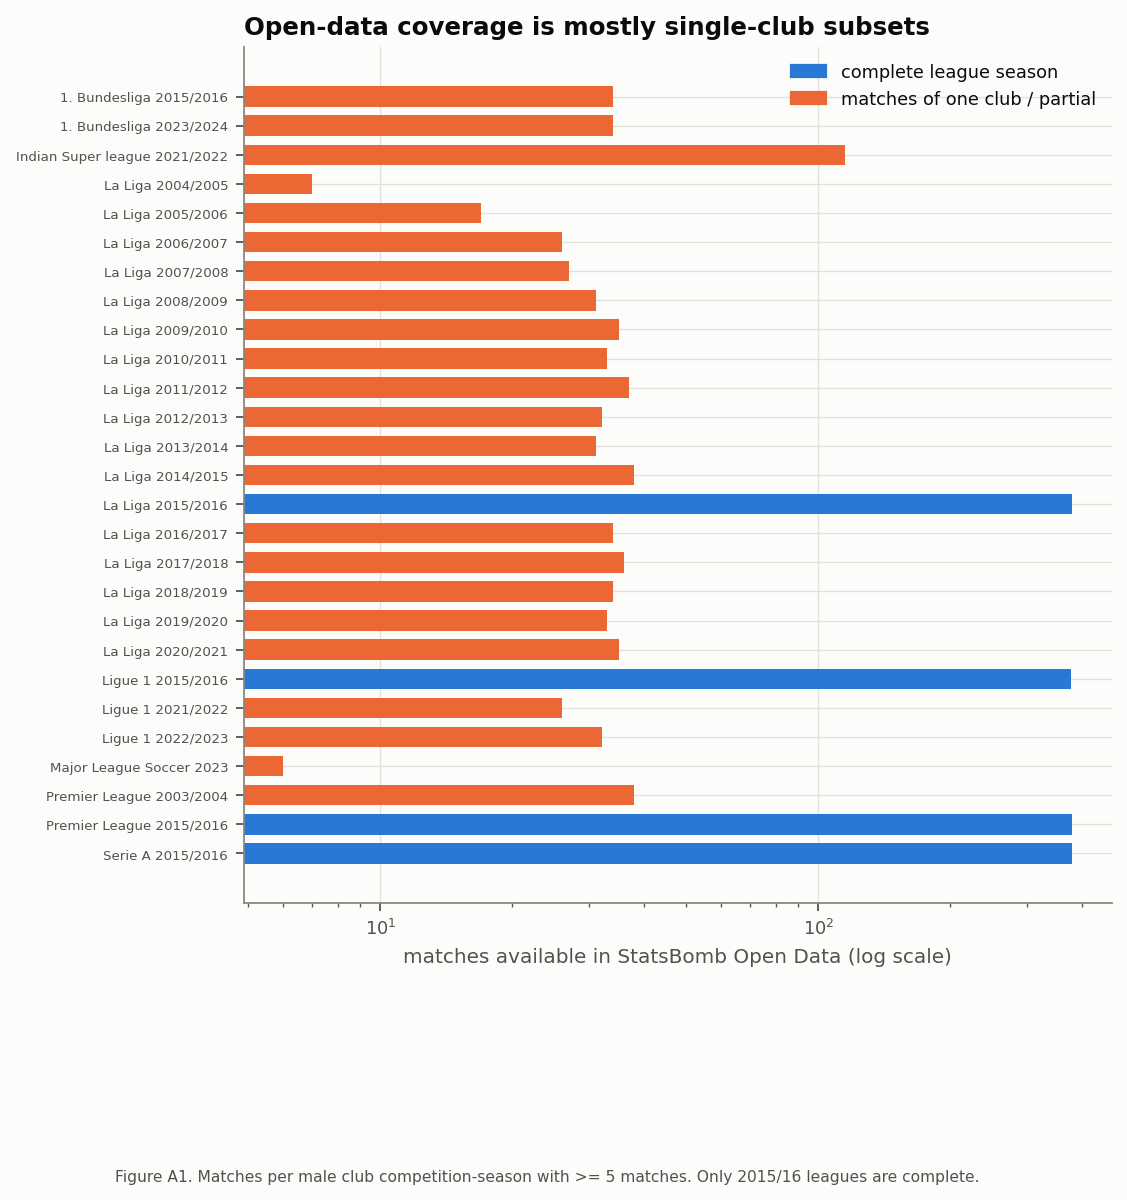

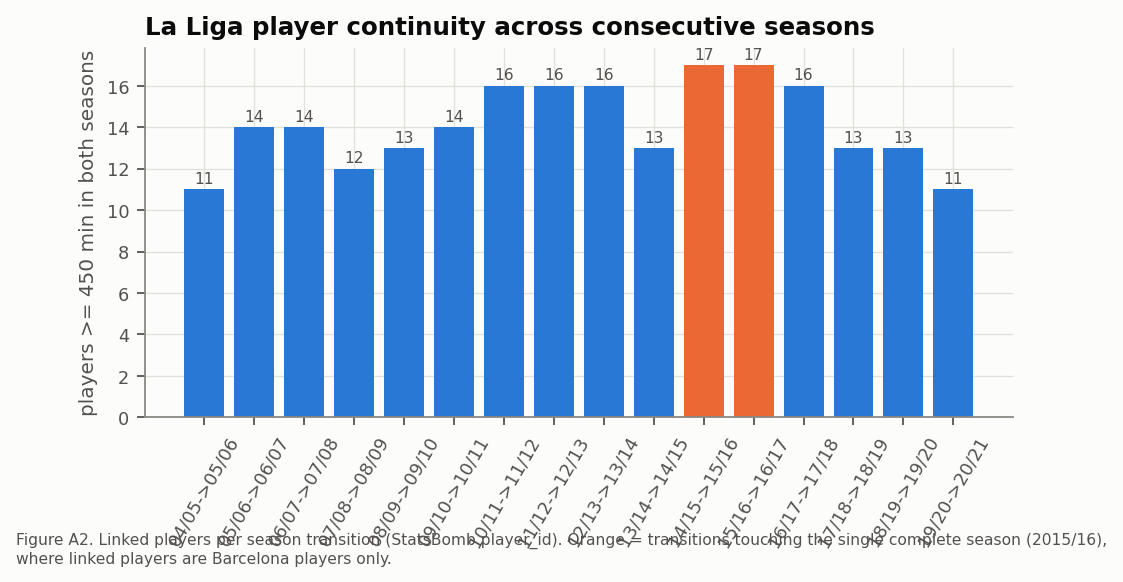

In [2]:
for f in ['audit/01_coverage_by_competition_season.png','audit/02_la_liga_player_continuity.png']:
    display(Image('figures/'+f))

## 2. Exposure, missingness, distributions

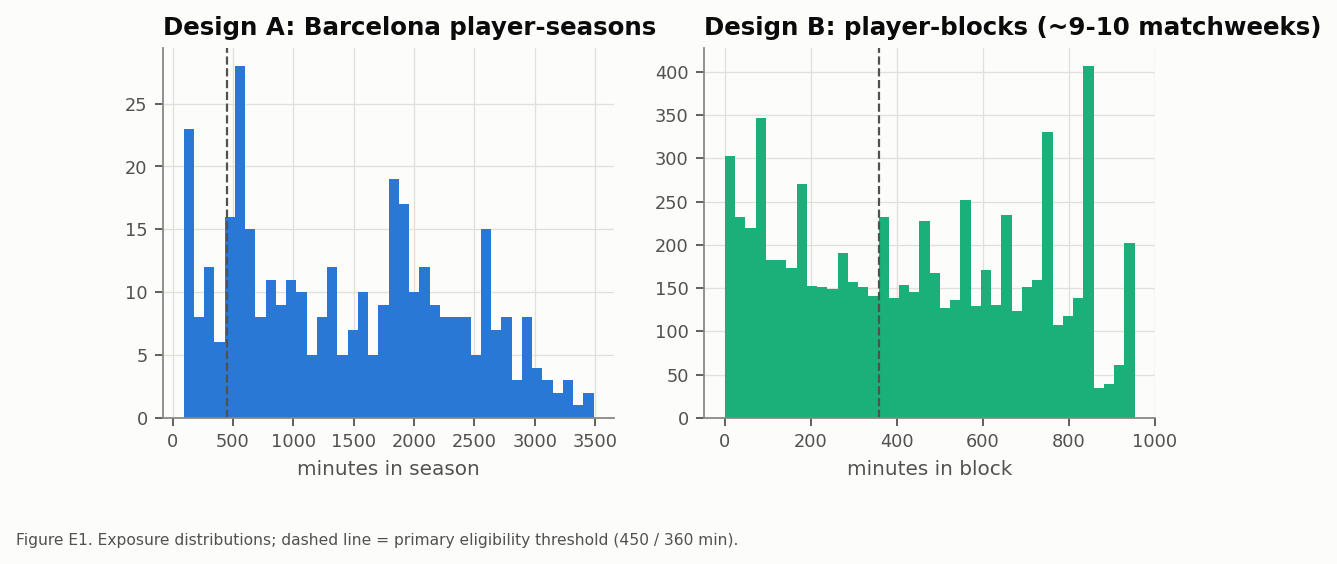

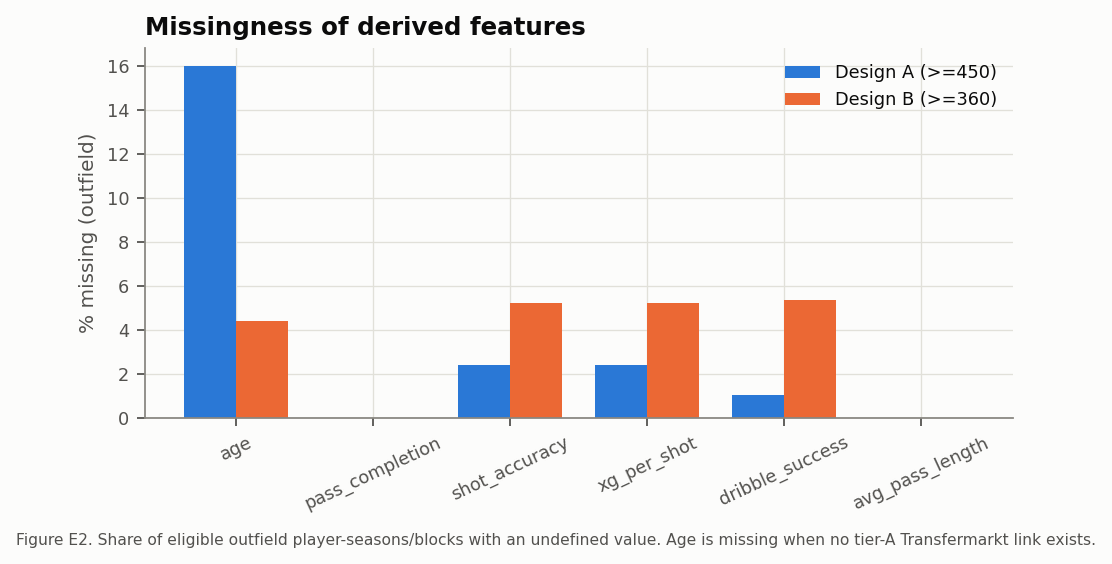

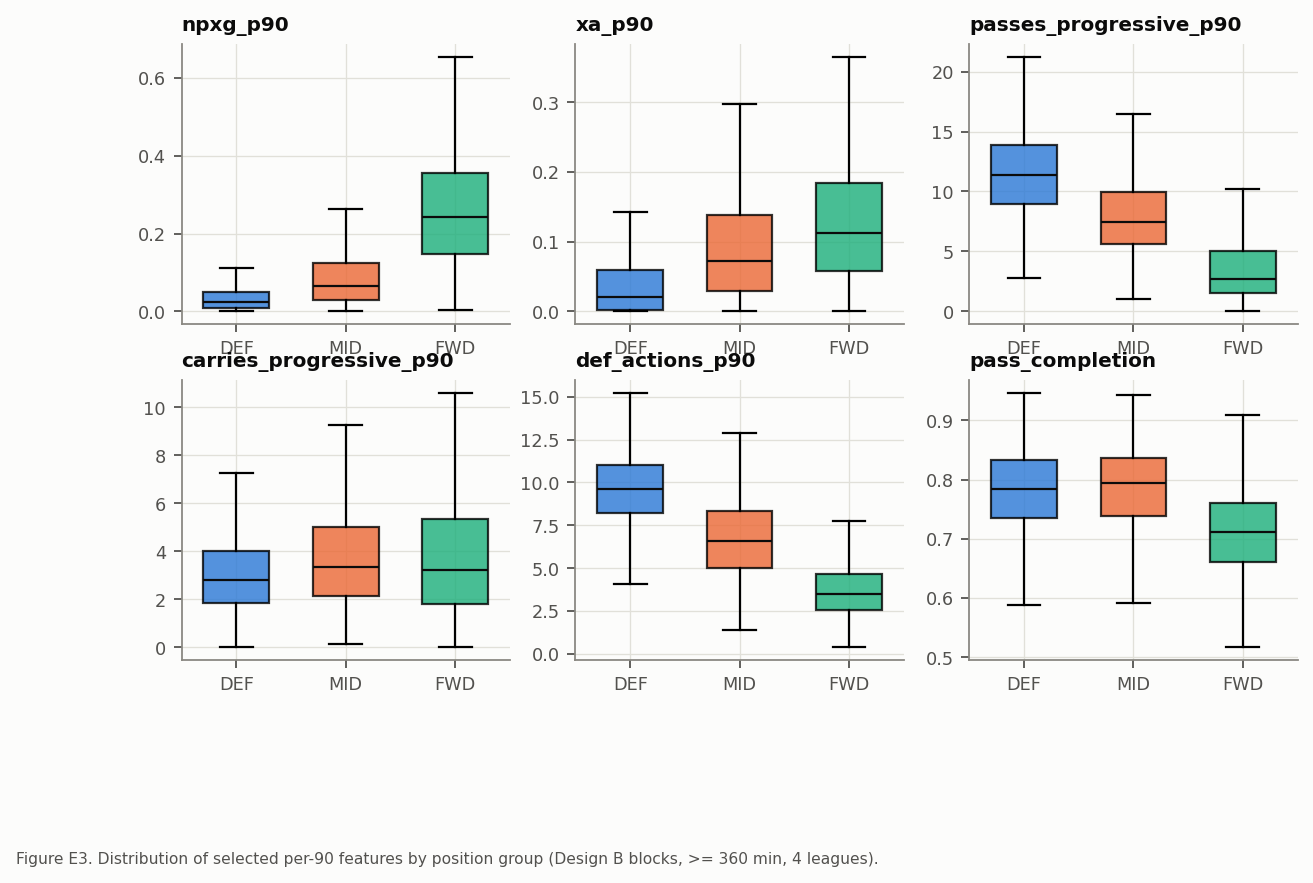

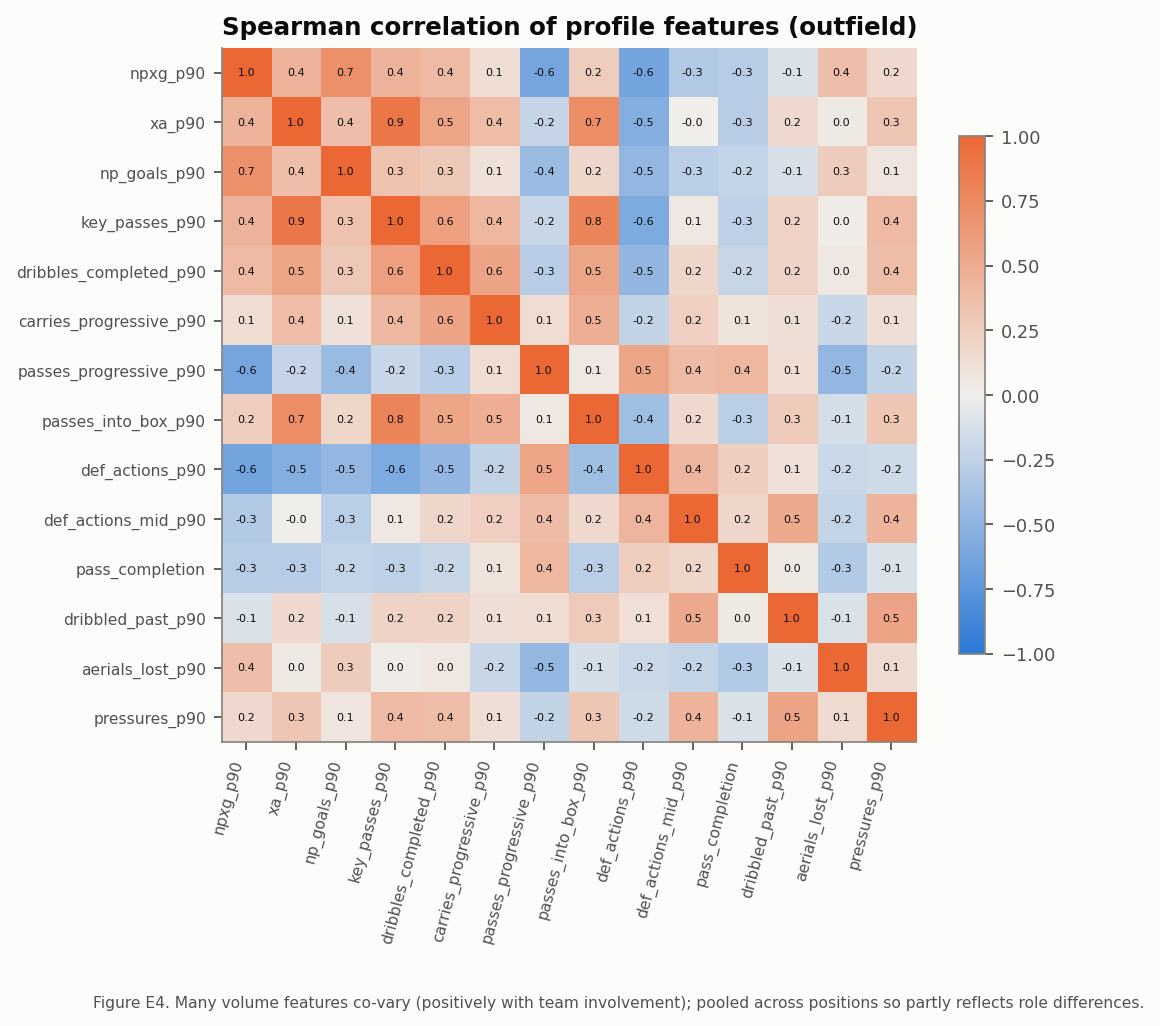

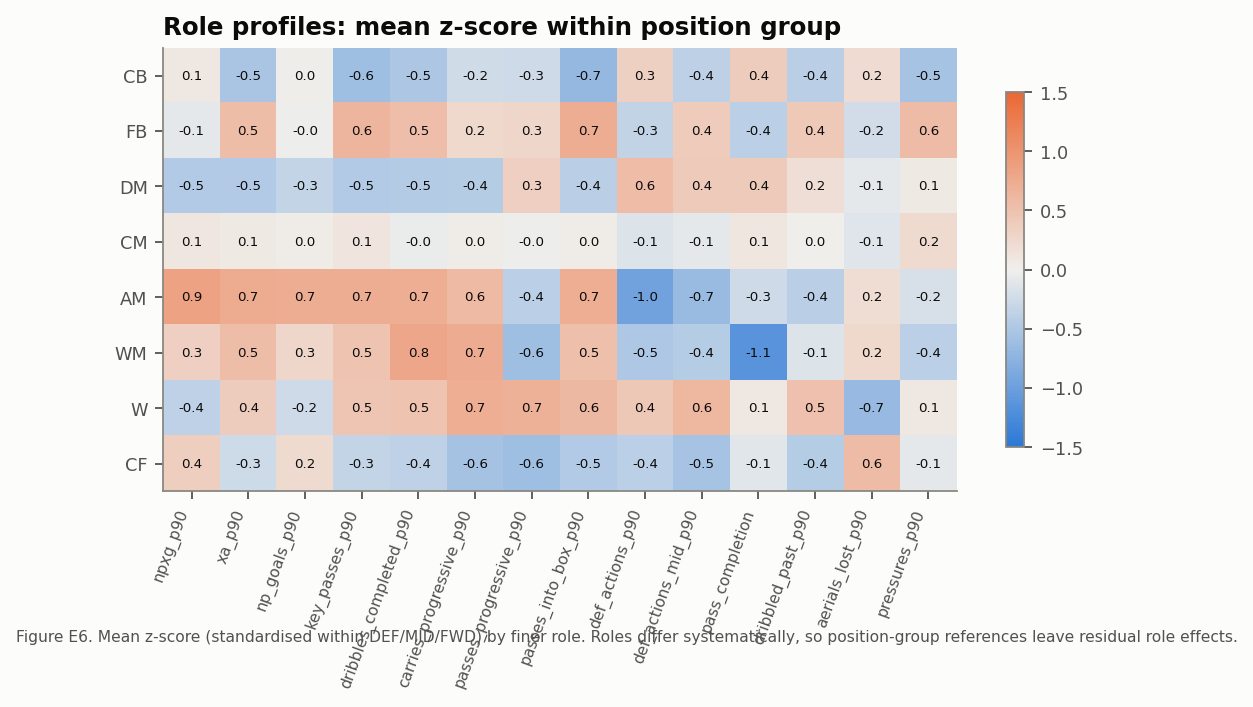

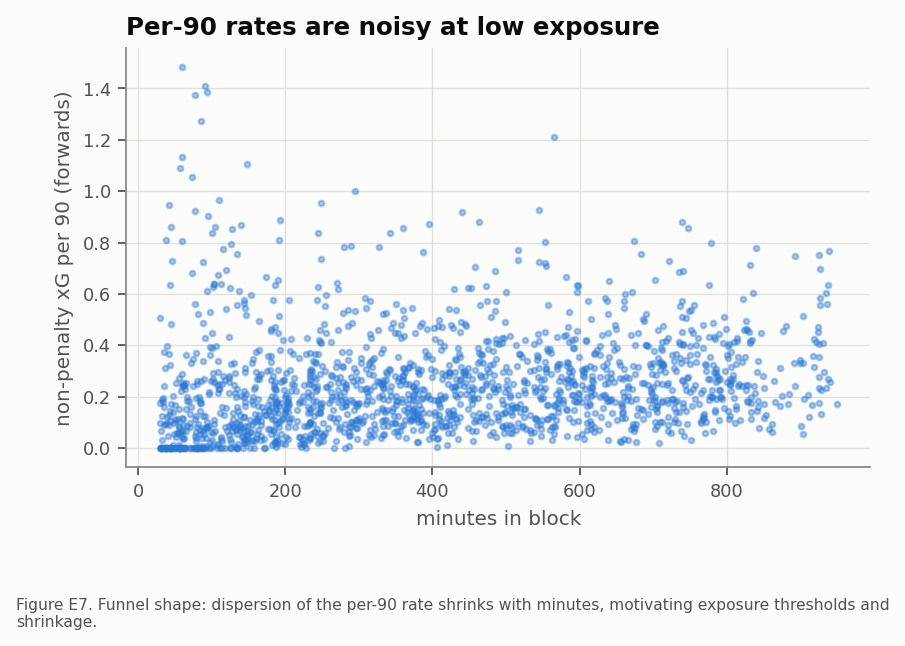

In [3]:
for f in ['eda/03_minutes_distribution.png','eda/04_missingness.png','eda/05_feature_distributions_by_position.png','eda/06_feature_correlations.png','eda/08_role_profiles.png','eda/09_exposure_and_rate_noise.png']:
    display(Image('figures/'+f))

## 3. Age, development, targets

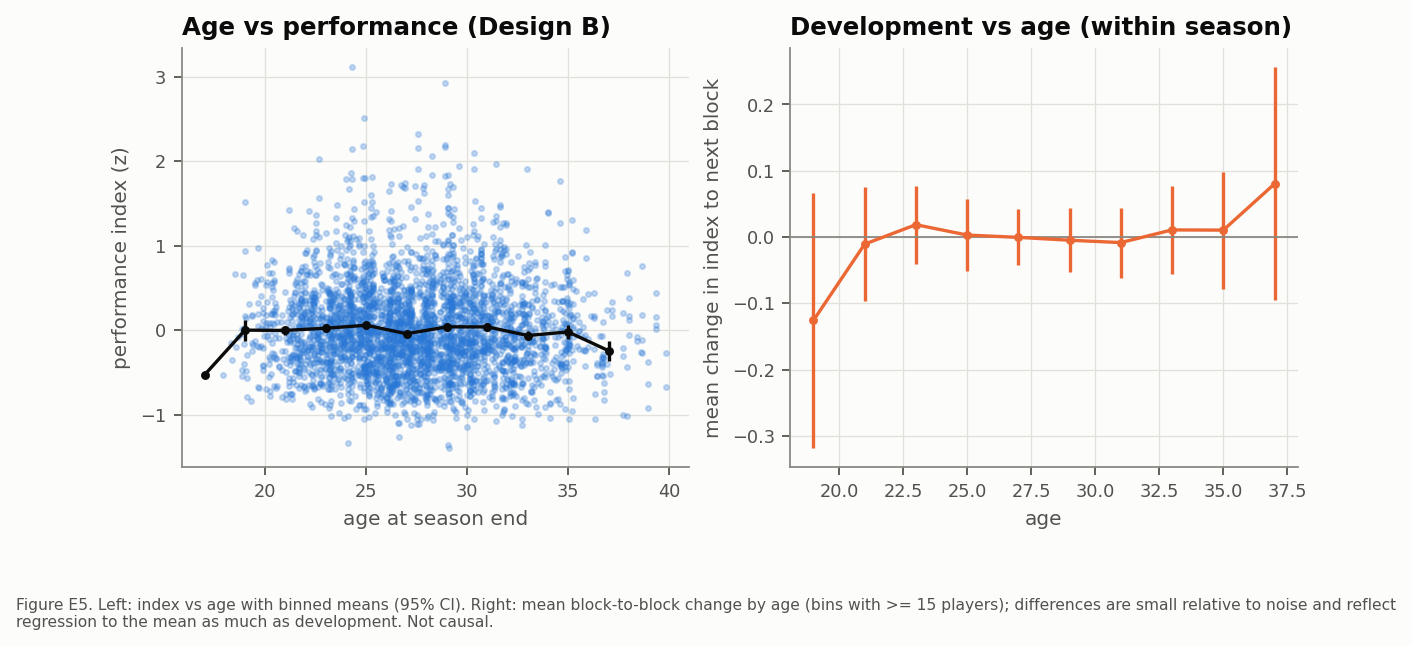

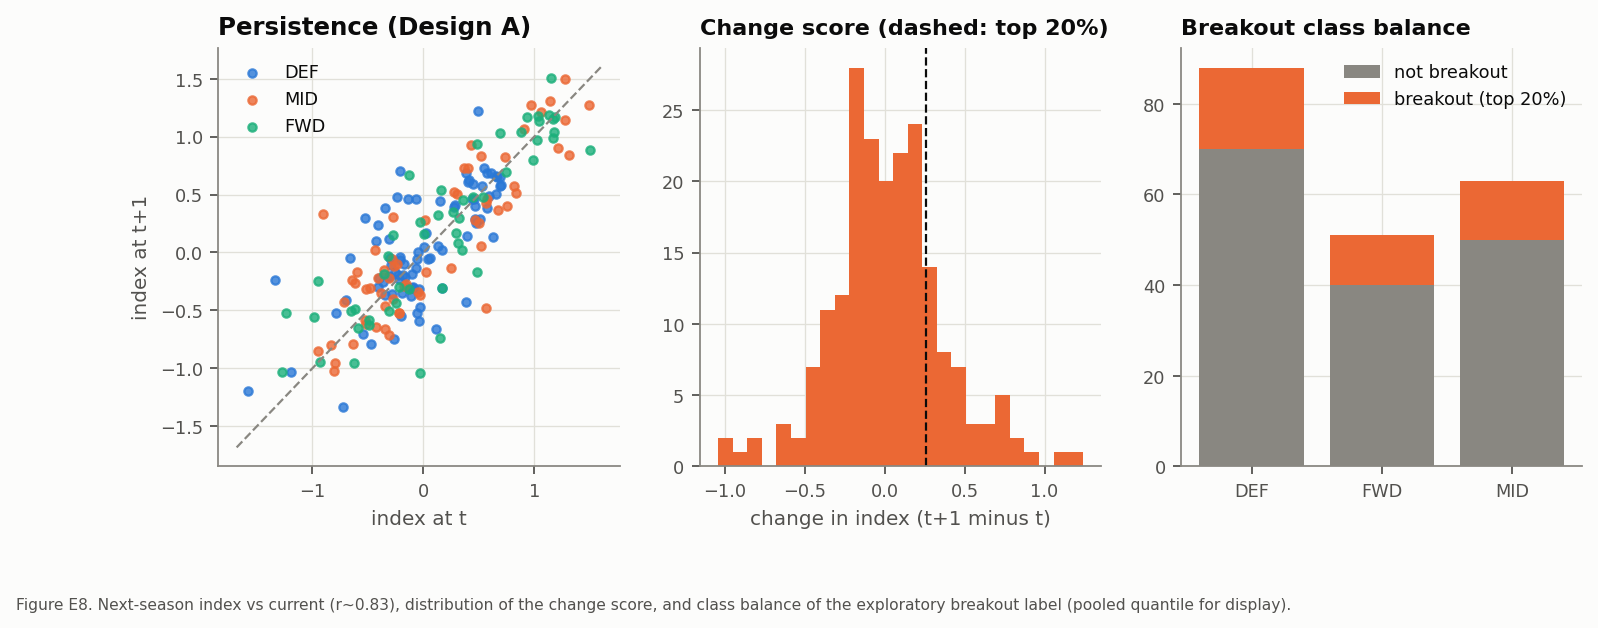

,age,mean,std,size
0,"(16, 22]",-0.132907,0.479707,27
1,"(22, 25]",-0.036028,0.580587,57
2,"(25, 28]",0.122706,0.525749,54
3,"(28, 31]",-0.051383,0.633351,60
4,"(31, 40]",0.137721,0.570308,49


In [4]:
display(Image('figures/eda/07_age_vs_performance_and_development.png'))
display(Image('figures/eda/10_target_distributions.png'))
pd.read_csv('reports/tables/age_profile_design_a.csv')

## 4. Measurement noise (split-half reliability) and attrition
The estimated noise SD of a season-to-season change is about as large as the observed SD of the change, i.e. next-season *change* in the index is mostly noise at this exposure.

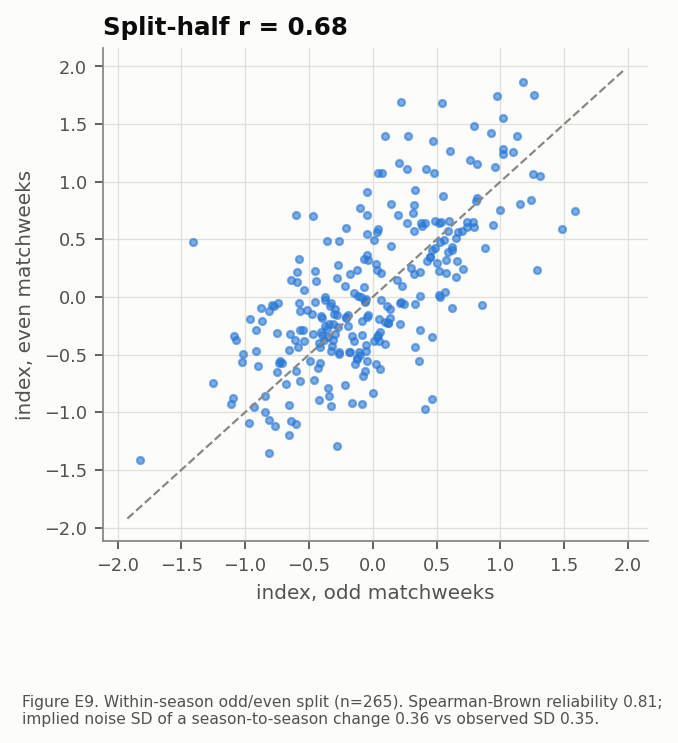

,0
n,265.000000
split_half_r,0.682572
spearman_brown_reliability,0.811344
sd_pi,0.585924
sem,0.254494
noise_sd_of_change,0.359908
observed_sd_of_change,0.350035
signal_share_of_change_variance,0.000000


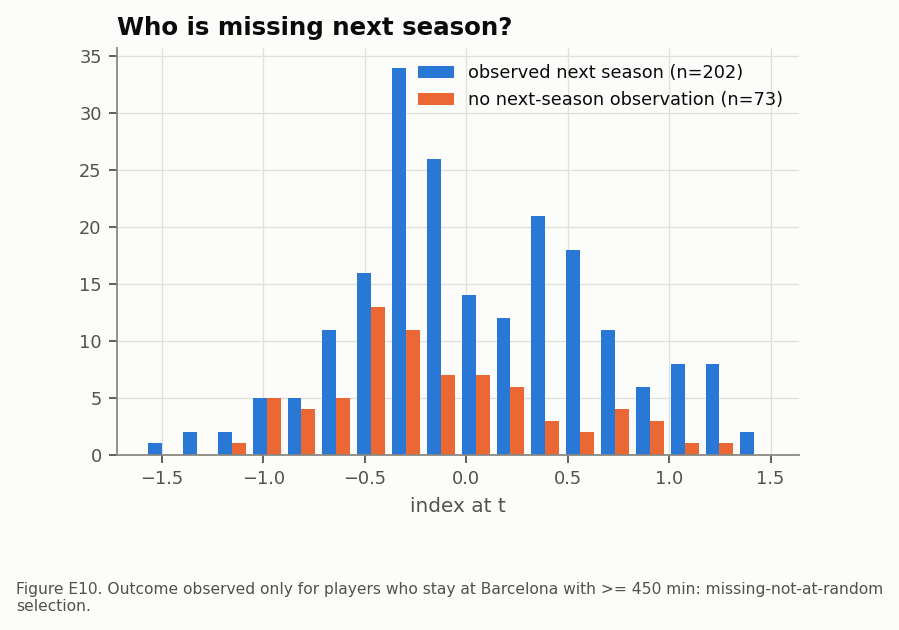

,n_retained,n_missing,mean_pi_retained,mean_pi_missing,mannwhitney_p
0,202,73,0.063881,-0.141803,0.007563


In [5]:
display(Image('figures/eda/11_split_half_reliability.png'))
display(pd.read_csv('reports/tables/reliability_design_a.csv').T)
display(Image('figures/eda/12_attrition_by_current_index.png'))
pd.read_csv('reports/tables/attrition_design_a.csv')

## 5. Confounders and market values

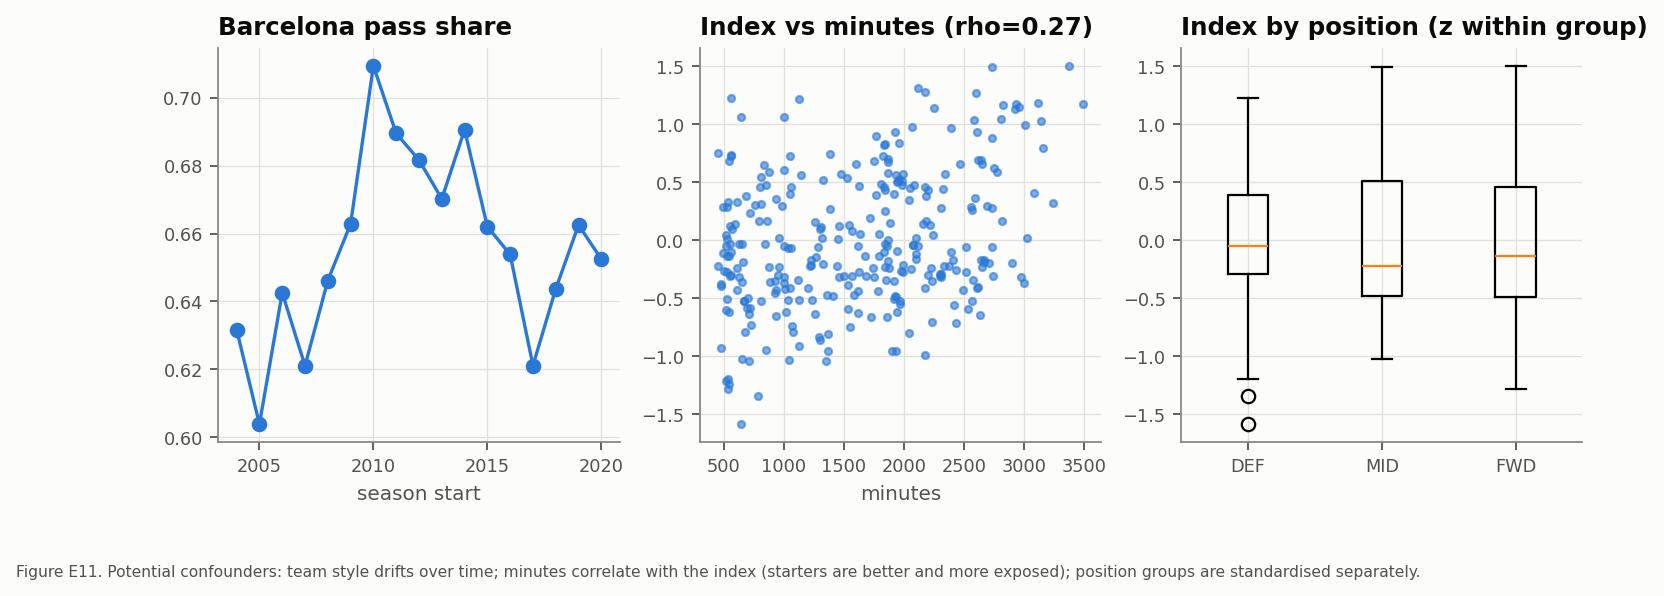

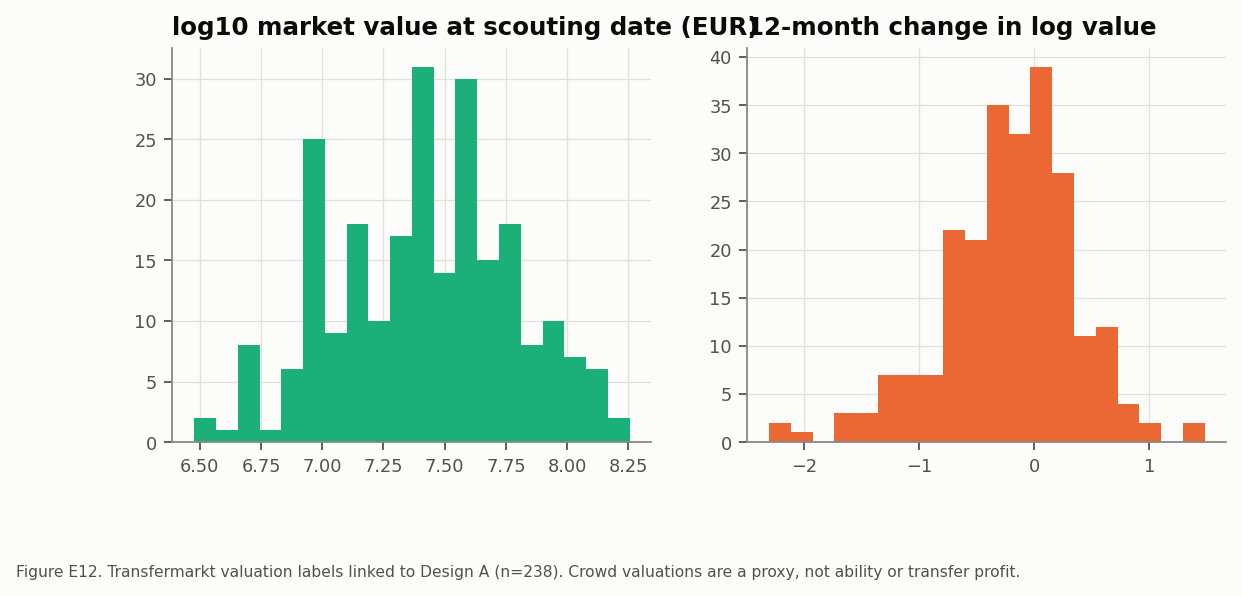

In [6]:
display(Image('figures/eda/13_confounders.png'))
display(Image('figures/eda/14_market_value_distributions.png'))